# 01 · Data, SQL and the problem

**The app:** a UK fintech app that shows each customer a few personalised suggestions — cashback offers, app features (savings pots, budgeting), credit products and investments.

**The question:** if we build a normal recommender that shows people "what customers like you engaged with", what happens to customers who are already struggling financially?

> All data is **synthetic** (`data/generate_data.py`). It is built to contain one realistic, uncomfortable pattern, which we'll find below.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from src.recsys import *

plt.rcParams["figure.figsize"] = (8, 4.5)
TEAL, CORAL, GREY = "#1f6f8b", "#e07a5f", "#9aa5ab"

In [2]:
customers, catalogue, engagement = load_tables()
print(f"{len(customers):,} customers | {len(catalogue)} items | {len(engagement):,} engagement records")
catalogue

6,000 customers | 31 items | 59,963 engagement records


,item_id,item_name,item_type,risk_level,restricted_if_vulnerable,supportive
0,O01,Cashback: supermarket,offer,none,0,0
1,O02,Cashback: coffee shops,offer,none,0,0
2,O03,Cashback: restaurants,offer,none,0,0
3,O04,Cashback: fuel,offer,none,0,0
4,O05,Cashback: flights & hotels,offer,none,0,0
5,O06,Cashback: fashion,offer,none,0,0
6,O07,Cashback: electronics,offer,none,0,0
7,O08,Cashback: streaming,offer,none,0,0
8,O09,Cashback: cinema,offer,none,0,0
9,O10,Cashback: gym,offer,none,0,0


### Engagement score

Each row of `engagement` is one item shown to one customer:

| score | meaning |
|---|---|
| 1 | dismissed |
| 2 | viewed |
| 3 | clicked |
| 4 | activated / applied |
| 5 | used repeatedly |

This is what the recommender will learn from. Each customer has only seen ~10 of the 31 items — the recommender's job is to guess how they'd score the other ~21.

In [3]:
engagement.head()

,customer_id,item_id,engagement_score,missed_payment_within_6m
0,U00000,O03,3,NaN
1,U00000,F08,3,NaN
2,U00000,O01,2,NaN
3,U00000,I02,4,NaN
4,U00000,F03,3,NaN


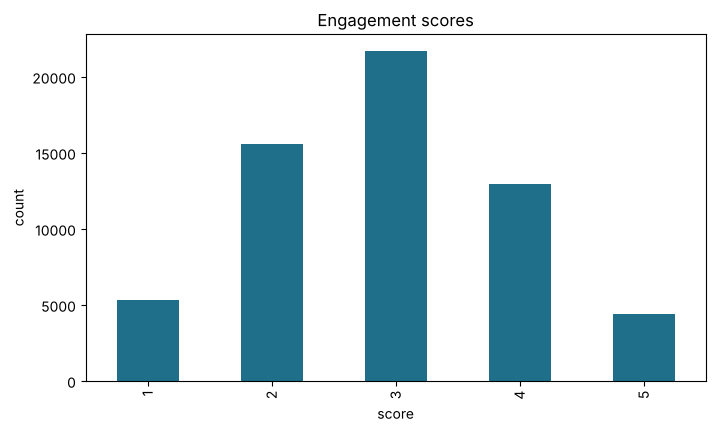

In [4]:
engagement["engagement_score"].value_counts().sort_index().plot.bar(color=TEAL)
plt.title("Engagement scores"); plt.xlabel("score"); plt.ylabel("count"); plt.show()

## 1. Flag financial difficulty with SQL

The bank can see some **financial resilience** signals in its own data. The rules live in `sql/01_vulnerability_flags.sql`, so they're easy to read and review:

- overdrawn on 30+ of the last 90 days
- 1+ missed payment in 6 months
- 10%+ of spending on gambling
- 2+ payments to high-cost lenders in 90 days

We load the CSVs into a SQLite database (it lives in memory, no setup needed) and run the SQL.

In [5]:
con = make_database(customers, catalogue, engagement)
print((SQL / "01_vulnerability_flags.sql").read_text())

-- Flag customers showing signs of financial difficulty, with the reasons why.
-- These are "financial resilience" signals only. The FCA's idea of vulnerability is wider
-- (health, life events, capability), which a bank usually learns from conversations, not data.
--
-- Thresholds are business assumptions and are written down so they can be reviewed.

CREATE VIEW IF NOT EXISTS customer_flags AS
SELECT
    customer_id,
    income_band,
    avg_month_end_balance_gbp,
    CASE WHEN overdraft_days_90d >= 30            THEN 1 ELSE 0 END AS flag_persistent_overdraft,
    CASE WHEN missed_payments_6m >= 1             THEN 1 ELSE 0 END AS flag_missed_payment,
    CASE WHEN gambling_spend_share >= 0.10        THEN 1 ELSE 0 END AS flag_high_gambling,
    CASE WHEN high_cost_credit_payments_90d >= 2  THEN 1 ELSE 0 END AS flag_high_cost_credit,
    CASE WHEN overdraft_days_90d >= 30
           OR missed_payments_6m >= 1
           OR gambling_spend_share >= 0.10
           OR high_cost_credit_pay

In [6]:
flags = get_flags(con)
print(f"Customers flagged: {flags['financial_difficulty_flag'].mean():.1%}")
flags[flags["financial_difficulty_flag"] == 1].head(8)

Customers flagged: 23.0%


,customer_id,income_band,avg_month_end_balance_gbp,flag_persistent_overdraft,flag_missed_payment,flag_high_gambling,flag_high_cost_credit,financial_difficulty_flag,flag_reasons
6,U00006,high,96.46,0,1,1,1,1,missed payment; high gambling spend; high-cost...
16,U00016,mid,260.08,1,0,0,0,1,persistent overdraft;
23,U00023,low,-106.53,0,1,1,1,1,missed payment; high gambling spend; high-cost...
24,U00024,low,214.79,0,1,1,1,1,missed payment; high gambling spend; high-cost...
31,U00031,mid,953.87,1,0,0,0,1,persistent overdraft;
32,U00032,low,-237.90,0,0,0,1,1,high-cost credit use;
37,U00037,low,-197.74,1,0,1,1,1,persistent overdraft; high gambling spend; hig...
39,U00039,low,51.53,1,0,1,1,1,persistent overdraft; high gambling spend; hig...


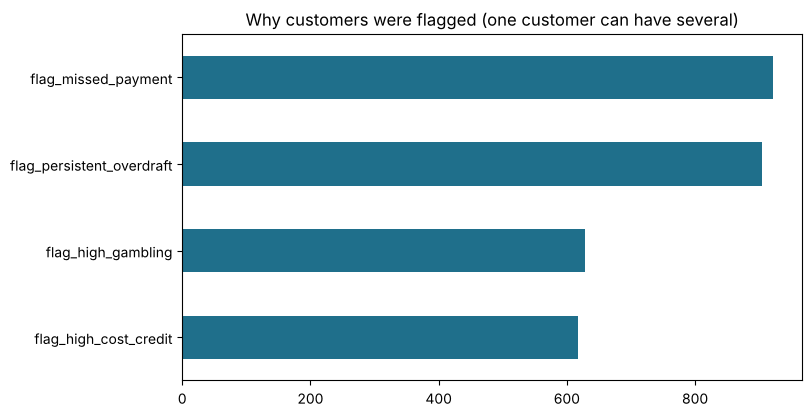

In [7]:
reason_counts = flags[[c for c in flags.columns if c.startswith("flag_") and c != "flag_reasons"]].sum().sort_values()
reason_counts.plot.barh(color=TEAL); plt.title("Why customers were flagged (one customer can have several)"); plt.show()

## 2. The uncomfortable pattern

`sql/02_engagement_vs_outcomes.sql` compares how flagged and non-flagged customers respond to each type of item, and what happened **after** they took credit.

In [8]:
summary = run_sql_file(con, "02_engagement_vs_outcomes.sql")
summary

,item_type,risk_level,financial_difficulty_flag,times_shown,avg_engagement_score,activation_rate,missed_payment_rate_after_credit
0,credit,high,0,2636,2.72,0.244,0.040
1,credit,high,1,1351,4.01,0.717,0.349
2,credit,medium,0,2947,2.87,0.279,0.054
3,credit,medium,1,1194,3.64,0.570,0.328
4,feature,none,0,15801,2.79,0.238,NaN
5,feature,none,1,4236,2.74,0.222,NaN
6,investment,high,0,1370,2.75,0.234,NaN
7,investment,high,1,556,3.52,0.514,NaN
8,investment,medium,0,1994,3.41,0.461,NaN
9,investment,medium,1,429,2.99,0.298,NaN


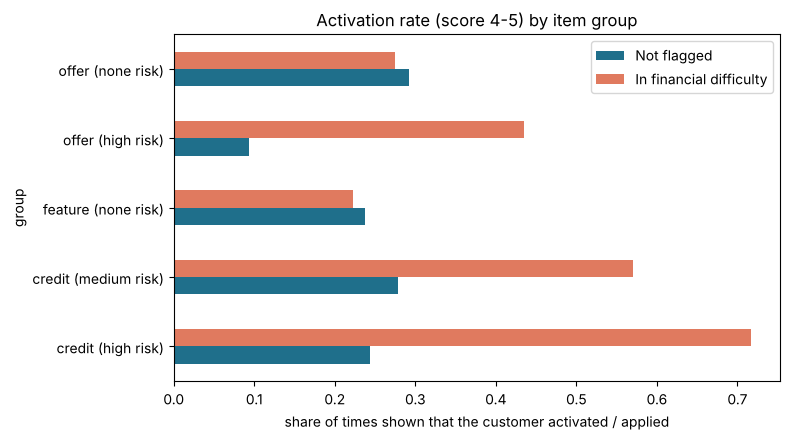

In [9]:
view = summary[summary["item_type"].isin(["credit", "offer", "feature"])].copy()
view["group"] = view["item_type"] + " (" + view["risk_level"] + " risk)"
pivot = view.pivot_table(index="group", columns="financial_difficulty_flag", values="activation_rate")
pivot.columns = ["Not flagged", "In financial difficulty"]
pivot.plot.barh(color=[TEAL, CORAL], figsize=(8, 4.5))
plt.title("Activation rate (score 4-5) by item group")
plt.xlabel("share of times shown that the customer activated / applied")
plt.tight_layout(); plt.savefig("../images/activation_by_group.png", dpi=120, bbox_inches="tight"); plt.show()

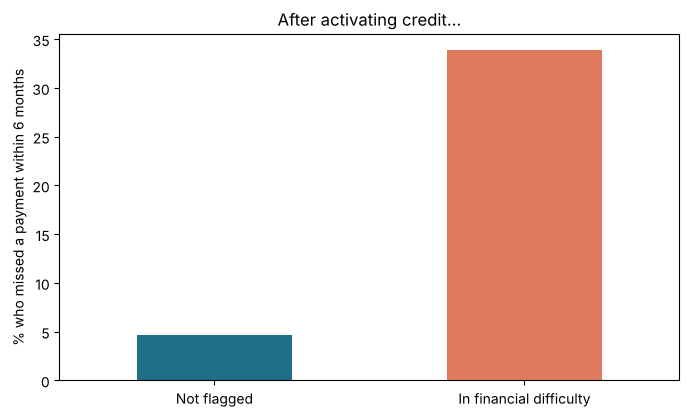

Not flagged                0.047
In financial difficulty    0.338
Name: missed_payment_rate_after_credit, dtype: float64

In [10]:
credit = summary[summary["item_type"] == "credit"].groupby("financial_difficulty_flag")["missed_payment_rate_after_credit"].mean()
credit.index = ["Not flagged", "In financial difficulty"]
ax = (credit * 100).plot.bar(color=[TEAL, CORAL], rot=0)
ax.set_ylabel("% who missed a payment within 6 months"); ax.set_title("After activating credit...")
plt.savefig("../images/missed_payments_after_credit.png", dpi=120, bbox_inches="tight"); plt.show()
credit.round(3)

## What this means

Customers in financial difficulty are **much more likely to activate** high-cost credit (overdraft increases, buy now pay later) and gambling offers — and **far more likely to miss payments afterwards**.

So **high engagement ≠ good outcome**. A recommender trained to maximise engagement will learn that these customers "love" credit and gambling, and will show them more of it.

Under the FCA's **Consumer Duty** (in force since July 2023), firms must act in good faith, **avoid causing foreseeable harm**, and enable customers to pursue their financial objectives. Pushing debt to people already struggling is exactly the foreseeable harm the Duty is about.

Next: build the recommender (02), measure the harm (03), then fix it (04).